# Vendas de Videogames — Análise de Mercado (1980–2016)

**Autor:** Leandro Gomes · [github.com/leandroanalytics](https://github.com/leandroanalytics)

Este notebook prepara a base usada no dashboard do Looker Studio e responde às perguntas de negócio do projeto.
Cada número citado no README e no dashboard é calculado aqui.

**Fonte:** base pública *Video Game Sales* (VGChartz, coletada em 2016), com 16.598 títulos que venderam ao menos 100 mil cópias.
Os valores de vendas estão em **milhões de unidades físicas vendidas**, não em receita.

## Perguntas de negócio

Perguntas pensadas do ponto de vista de um gestor de uma publisher ou de uma varejista de games:

1. **Como o mercado evoluiu e quando foi o auge?** Ajuda a entender o ciclo de vida das gerações de console.
2. **Quanto as vendas dependem de poucos sucessos?** Define o risco de portfólio: apostar em poucos *blockbusters* ou em muitos títulos.
3. **Onde estão as vendas por região?** Orienta a distribuição de verba de marketing e de estoque.
4. **As preferências de gênero mudam entre regiões?** Mostra se um mesmo lançamento global funciona igual em todo lugar.
5. **Quais fabricantes e plataformas dominam?** Indica para qual console lançar.
6. **Quais publishers lideram e quem é mais eficiente por título?** Separa quem vende por volume de quem vende por qualidade de catálogo.
7. **Quais gêneros vendem mais por título lançado?** Revela gêneros com menos concorrência e maior retorno médio.

### O que esta base **não** responde
- **Receita, preço e margem:** só há unidades vendidas.
- **Vendas digitais** (Steam, PSN, eShop): a base cobre apenas mídia física.
- **Mercado depois de 2016:** a coleta parou em 2016, e esse ano está incompleto.
- **Jogos com menos de 100 mil cópias:** a "cauda longa" de lançamentos ficou fora da base.
- **Mercado brasileiro:** o Brasil está agregado em "Outras regiões".
- **Causalidade:** a base mostra o que vendeu, não por que vendeu (preço, marketing e notas da crítica não estão disponíveis).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')
AZUL, CINZA = '#1a73e8', '#9aa0a6'
GRAF = '../imagens/graficos/'
import os; os.makedirs(GRAF, exist_ok=True)

raw = pd.read_csv('../dados/vgsales_original.csv', dtype={'Year': 'Int64'})
raw.shape

(16598, 11)

## 1. Qualidade dos dados

In [2]:
REG = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
VEND = REG + ['Global_Sales']

print('Nulos por coluna:'); print(raw.isna().sum()[raw.isna().sum() > 0])
print('\nLinhas totalmente duplicadas:', raw.duplicated().sum())
print('Duplicadas por Nome + Plataforma + Ano:', raw.duplicated(['Name', 'Platform', 'Year']).sum())
print('\nJogos por ano (anos finais):'); print(raw['Year'].value_counts().sort_index().tail(5))
dif = (raw[REG].sum(axis=1) - raw['Global_Sales']).abs()
print(f'\nMaior diferença entre a soma das regiões e Global_Sales numa linha: {dif.max():.2f} (arredondamento da fonte)')

Nulos por coluna:
Year         271
Publisher     58
dtype: int64

Linhas totalmente duplicadas: 0
Duplicadas por Nome + Plataforma + Ano: 2

Jogos por ano (anos finais):
Year
2014    582
2015    614
2016    344
2017      3
2020      1
Name: count, dtype: Int64

Maior diferença entre a soma das regiões e Global_Sales numa linha: 0.02 (arredondamento da fonte)


In [3]:
raw[raw.duplicated(['Name', 'Platform', 'Year'], keep=False)]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
603,604,Madden NFL 13,PS3,2012,Sports,Electronic Arts,2.11,0.23,0.00,0.22,2.56
14997,15000,Wii de Asobu: Metroid Prime,Wii,<NA>,Shooter,Nintendo,0.00,0.00,0.02,0.00,0.02
14999,15002,Wii de Asobu: Metroid Prime,Wii,<NA>,Shooter,Nintendo,0.00,0.00,0.02,0.00,0.02
16127,16130,Madden NFL 13,PS3,2012,Sports,Electronic Arts,0.00,0.01,0.00,0.00,0.01


**Decisões de tratamento**

| Problema | Linhas | Decisão |
| --- | ---: | --- |
| `Year` vazio | 271 | Mantidas nos totais; ficam fora apenas da análise por ano |
| `Publisher` vazio | 58 | Preenchido como `Unknown` (padrão que a própria fonte já usa) |
| Registros duplicados (Madden NFL 13 – PS3; Wii de Asobu: Metroid Prime – Wii) | 2 | Somados ao registro principal |
| Anos 2017 e 2020 | 4 | Erros de cadastro (lançamentos futuros na data da coleta); removidos da série temporal |
| Ano 2016 | 344 | Coleta incompleta; aparece na base, mas é sinalizado e fica fora das conclusões de tendência |

In [4]:
df = raw.copy()
df['Publisher'] = df['Publisher'].fillna('Unknown')

# Junta os 2 registros duplicados, somando as vendas
chave = ['Name', 'Platform', 'Year']
agg = {'Rank': 'min', 'Genre': 'first', 'Publisher': 'first', **{c: 'sum' for c in VEND}}
df = df.groupby(chave, dropna=False, as_index=False, sort=False).agg(agg)
df['Year'] = df['Year'].astype('Int64')

fabricante = {
    'Nintendo': ['Wii', 'NES', 'GB', 'DS', 'SNES', 'GBA', '3DS', 'N64', 'GC', 'WiiU'],
    'Sony': ['PS', 'PS2', 'PS3', 'PS4', 'PSP', 'PSV'],
    'Microsoft': ['XB', 'X360', 'XOne'],
    'Sega': ['GEN', 'SCD', 'SAT', 'DC', 'GG'],
    'PC': ['PC'],
}
mapa = {p: f for f, ps in fabricante.items() for p in ps}
df['Fabricante'] = df['Platform'].map(mapa).fillna('Outros')

portateis = ['GB', 'GBA', 'DS', '3DS', 'PSP', 'PSV', 'GG', 'WS']
df['Tipo_Plataforma'] = np.select(
    [df['Platform'].eq('PC'), df['Platform'].isin(portateis)], ['PC', 'Portátil'], 'Console de mesa')

genero_pt = {'Action': 'Ação', 'Sports': 'Esportes', 'Shooter': 'Tiro', 'Role-Playing': 'RPG',
             'Platform': 'Plataforma', 'Misc': 'Diversos', 'Racing': 'Corrida', 'Fighting': 'Luta',
             'Simulation': 'Simulação', 'Puzzle': 'Quebra-cabeça', 'Adventure': 'Aventura', 'Strategy': 'Estratégia'}
df['Genero_PT'] = df['Genre'].map(genero_pt)

df['Decada'] = (df['Year'] // 10 * 10).astype('string') + 's'
df['Ano_Completo'] = np.where(df['Year'].between(1980, 2015).fillna(False).astype(bool), 'Sim', 'Não')

df = df.sort_values('Rank').reset_index(drop=True)
df.to_csv('../dados/vgsales_tratado.csv', index=False)
print(df.shape); df.head()

(16596, 16)


,Name,Platform,Year,Rank,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Fabricante,Tipo_Plataforma,Genero_PT,Decada,Ano_Completo
0,Wii Sports,Wii,2006,1,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,Nintendo,Console de mesa,Esportes,2000s,Sim
1,Super Mario Bros.,NES,1985,2,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,Nintendo,Console de mesa,Plataforma,1980s,Sim
2,Mario Kart Wii,Wii,2008,3,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,Nintendo,Console de mesa,Corrida,2000s,Sim
3,Wii Sports Resort,Wii,2009,4,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,Nintendo,Console de mesa,Esportes,2000s,Sim
4,Pokemon Red/Pokemon Blue,GB,1996,5,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,Nintendo,Portátil,RPG,1990s,Sim


## 2. Indicadores principais

In [5]:
tot = df[VEND].sum()
kpi = pd.DataFrame({'Milhões de unidades': tot, '% do global': tot / tot['Global_Sales'] * 100})
kpi.index = ['América do Norte', 'Europa', 'Japão', 'Outras regiões', 'Global']
print(f'Títulos: {len(df):,} | Plataformas: {df.Platform.nunique()} | Publishers: {df.Publisher.nunique()} | Gêneros: {df.Genre.nunique()}')
print(f'Soma das 4 regiões: {tot[REG].sum():,.2f} vs Global: {tot.Global_Sales:,.2f} (diferença de arredondamento da fonte)')
kpi

Títulos: 16,596 | Plataformas: 31 | Publishers: 578 | Gêneros: 12
Soma das 4 regiões: 8,915.85 vs Global: 8,920.44 (diferença de arredondamento da fonte)


,Milhões de unidades,% do global
América do Norte,"4,392.95",49.25
Europa,"2,434.13",27.29
Japão,"1,291.02",14.47
Outras regiões,797.75,8.94
Global,"8,920.44",100.00


## Pergunta 1 — Como o mercado evoluiu e quando foi o auge?

Pico de vendas: 2008 (678.9 mi) | Pico de lançamentos: 2009 (1,431 títulos)
Vendas 2015 vs pico: -61%


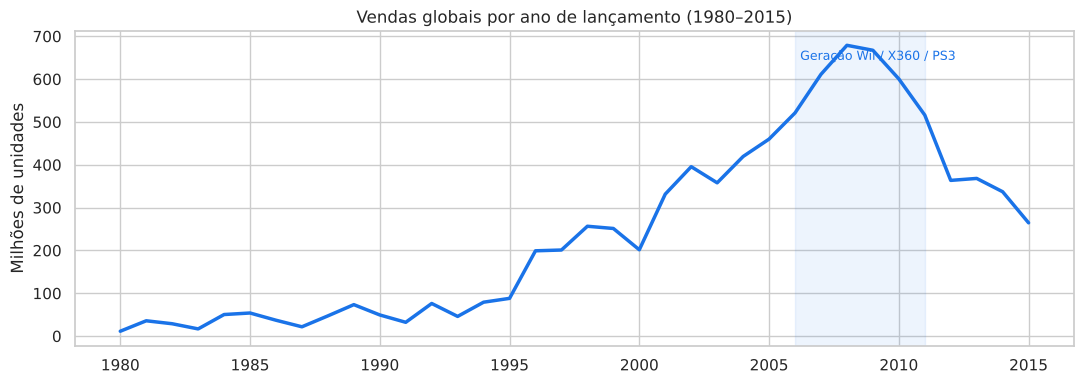

In [6]:
serie = (df[df['Ano_Completo'] == 'Sim']
         .groupby('Year').agg(vendas=('Global_Sales', 'sum'), lancamentos=('Name', 'size')))
pico_v, pico_l = serie['vendas'].idxmax(), serie['lancamentos'].idxmax()
print(f'Pico de vendas: {pico_v} ({serie.vendas.max():,.1f} mi) | Pico de lançamentos: {pico_l} ({serie.lancamentos.max():,} títulos)')
print(f'Vendas 2015 vs pico: {serie.loc[2015, "vendas"] / serie.vendas.max() - 1:.0%}')

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(serie.index, serie['vendas'], color=AZUL, lw=2.5)
ax.axvspan(2006, 2011, color=AZUL, alpha=.08)
ax.text(2006.2, serie.vendas.max() * 0.95, 'Geração Wii / X360 / PS3', fontsize=9, color=AZUL)
ax.set(title='Vendas globais por ano de lançamento (1980–2015)', xlabel='', ylabel='Milhões de unidades')
plt.tight_layout(); plt.savefig(GRAF + '01_evolucao.png', dpi=150); plt.show()

**Leitura:** o mercado cresceu de forma contínua até o pico de **2008** e caiu a partir de 2010.

**Cuidado ao interpretar a queda:** parte dela vem da própria base. Jogos recentes tiveram menos tempo para acumular vendas, e a migração para o digital não aparece aqui. Ou seja, a base mostra o **fim do auge da mídia física**, não necessariamente o encolhimento do mercado de games.

## Pergunta 2 — Quanto as vendas dependem de poucos sucessos?

Top   1% dos títulos (  165 jogos) = 21.0% das vendas
Top   5% dos títulos (  829 jogos) = 44.5% das vendas
Top  10% dos títulos (1,659 jogos) = 58.8% das vendas
Top  20% dos títulos (3,319 jogos) = 74.8% das vendas

Mediana de vendas por título: 0.17 mi | Média: 0.54 mi
Os 101 maiores sucessos (base do projeto anterior) = 16.5% das vendas


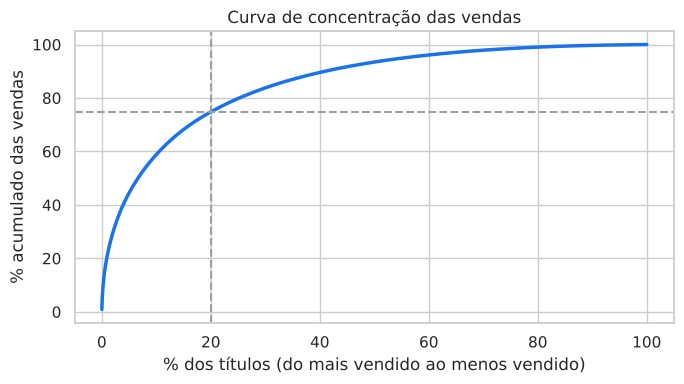

In [7]:
s = df['Global_Sales'].sort_values(ascending=False).reset_index(drop=True)
acum = s.cumsum() / s.sum()
for p in [0.01, 0.05, 0.10, 0.20]:
    n = int(len(s) * p)
    print(f'Top {p:>4.0%} dos títulos ({n:>5,} jogos) = {acum[n - 1]:.1%} das vendas')
print(f'\nMediana de vendas por título: {s.median():.2f} mi | Média: {s.mean():.2f} mi')
print(f'Os 101 maiores sucessos (base do projeto anterior) = {s[:101].sum() / s.sum():.1%} das vendas')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(s) + 1) / len(s) * 100, acum * 100, color=AZUL, lw=2.5)
ax.axvline(20, color=CINZA, ls='--'); ax.axhline(acum[int(len(s) * .2) - 1] * 100, color=CINZA, ls='--')
ax.set(title='Curva de concentração das vendas', xlabel='% dos títulos (do mais vendido ao menos vendido)', ylabel='% acumulado das vendas')
plt.tight_layout(); plt.savefig(GRAF + '02_concentracao.png', dpi=150); plt.show()

**Leitura:** o mercado é movido por *hits*. **1% dos títulos responde por cerca de 21% das vendas**, e 20% respondem por três quartos. A média por título (0,54 mi) é mais que o triplo da mediana (0,17 mi), sinal de distribuição muito assimétrica.

**Implicação para o gestor:** a "média de vendas" engana. Para projetar um lançamento, a mediana é a referência mais realista, e o portfólio precisa de títulos âncora.

## Pergunta 3 — Onde estão as vendas por região?

América do Norte    49.3%
Europa              27.3%
Japão               14.5%
Outras regiões       8.9%
dtype: str

Participação do Japão por década:
Decada
1980s   27.20
1990s   29.10
2000s   11.00
2010s   11.60
dtype: float64


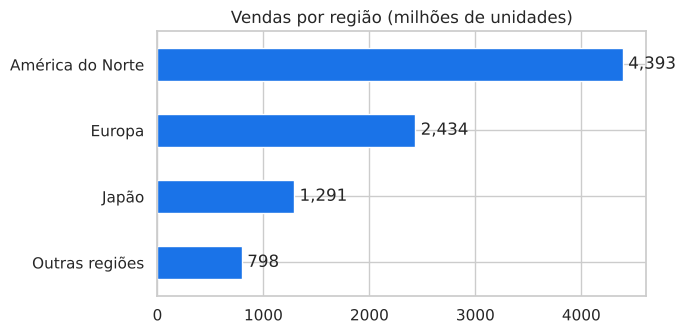

In [8]:
reg = tot[REG].rename({'NA_Sales': 'América do Norte', 'EU_Sales': 'Europa', 'JP_Sales': 'Japão', 'Other_Sales': 'Outras regiões'})
print((reg / reg.sum() * 100).round(1).astype(str) + '%')

jp = df[df['Ano_Completo'] == 'Sim'].groupby('Year')[['JP_Sales', 'Global_Sales']].sum()
jp_share = (jp['JP_Sales'] / jp['Global_Sales'] * 100)
print('\nParticipação do Japão por década:')
print(df[df['Ano_Completo'] == 'Sim'].groupby('Decada').apply(lambda g: g.JP_Sales.sum() / g.Global_Sales.sum() * 100, include_groups=False).round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
reg.sort_values().plot.barh(ax=ax, color=AZUL)
for i, v in enumerate(reg.sort_values()): ax.text(v + 50, i, f'{v:,.0f}', va='center')
ax.set(title='Vendas por região (milhões de unidades)', xlabel='')
plt.tight_layout(); plt.savefig(GRAF + '03_regioes.png', dpi=150); plt.show()

**Leitura:** a **América do Norte concentra quase metade (49%) das vendas**, seguida da Europa (27%). O Japão, que nos anos 80 e 90 era peça central do mercado, perdeu peso relativo nos anos 2000.

## Pergunta 4 — As preferências de gênero mudam entre regiões?

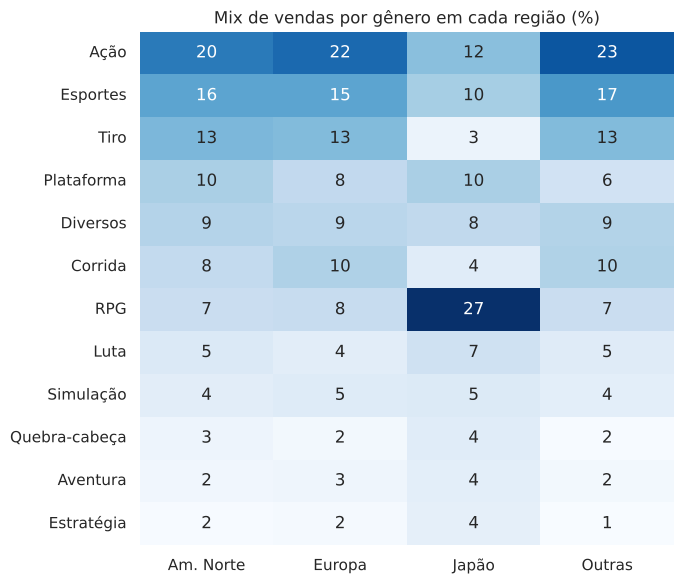

,Am. Norte,Europa,Japão,Outras
Genero_PT,,,,
Ação,20.00,21.60,12.40,23.50
Esportes,15.60,15.50,10.50,16.90
Tiro,13.30,12.90,3.00,12.90
Plataforma,10.20,8.30,10.10,6.50
Diversos,9.30,8.90,8.30,9.40
Corrida,8.20,9.80,4.40,9.70
RPG,7.50,7.70,27.30,7.50
Luta,5.10,4.20,6.80,4.60
Simulação,4.20,4.70,4.90,4.00


In [9]:
gr = df.groupby('Genero_PT')[REG].sum()
mix = (gr / gr.sum() * 100).rename(columns={'NA_Sales': 'Am. Norte', 'EU_Sales': 'Europa', 'JP_Sales': 'Japão', 'Other_Sales': 'Outras'})
mix = mix.sort_values('Am. Norte', ascending=False)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(mix, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=ax)
ax.set(title='Mix de vendas por gênero em cada região (%)', xlabel='', ylabel='')
plt.tight_layout(); plt.savefig(GRAF + '04_genero_regiao.png', dpi=150); plt.show()
mix.round(1)

**Leitura:** a diferença é grande. **RPG representa 27% das vendas no Japão e apenas 7–8% no Ocidente**, enquanto **Tiro tem 13% na América do Norte e na Europa e só 3% no Japão**.

**Implicação para o gestor:** um lançamento global de tiro deve concentrar marketing e estoque no Ocidente; um RPG precisa de estratégia própria para o Japão. Um único plano global desperdiça verba.

## Pergunta 5 — Quais fabricantes e plataformas dominam?

In [10]:
fab = df.groupby('Fabricante')['Global_Sales'].sum().sort_values(ascending=False)
print((fab / fab.sum() * 100).round(1).astype(str) + '%')

plat = df.groupby('Platform').agg(vendas=('Global_Sales', 'sum'), titulos=('Name', 'size'))
plat['media_por_titulo'] = plat['vendas'] / plat['titulos']
print('\nTop 10 plataformas:')
print(plat.sort_values('vendas', ascending=False).head(10).round(2))

tipo = df.groupby('Tipo_Plataforma')['Global_Sales'].sum()
print('\nPor tipo:'); print((tipo / tipo.sum() * 100).round(1).astype(str) + '%')

Fabricante
Sony         40.1%
Nintendo     39.5%
Microsoft    15.5%
PC            2.9%
Outros        1.1%
Sega          0.9%
Name: Global_Sales, dtype: str

Top 10 plataformas:
           vendas  titulos  media_por_titulo
Platform                                    
PS2      1,255.64     2161              0.58
X360       979.96     1265              0.77
PS3        957.84     1328              0.72
Wii        926.71     1324              0.70
DS         822.49     2163              0.38
PS         730.66     1196              0.61
GBA        318.50      822              0.39
PSP        296.28     1213              0.24
PS4        278.10      336              0.83
PC         258.82      960              0.27

Por tipo:
Tipo_Plataforma
Console de mesa    74.6%
PC                  2.9%
Portátil           22.5%
Name: Global_Sales, dtype: str


**Leitura:** **Sony (40%) e Nintendo (39,5%)** praticamente empatam no acumulado, com a Microsoft bem atrás (15,5%). Consoles de mesa respondem por 75% das vendas e portáteis por 22,5%. O **PS2 é a plataforma mais vendida da história da base**, mas com média de vendas por título menor que a de X360, PS3, Wii e PS4. Ou seja, é um catálogo enorme, com muitos títulos de venda modesta.

## Pergunta 6 — Quais publishers lideram e quem é mais eficiente por título?

In [11]:
pub = df.groupby('Publisher').agg(vendas=('Global_Sales', 'sum'), titulos=('Name', 'size'))
pub['share_%'] = pub['vendas'] / pub['vendas'].sum() * 100
pub['media_por_titulo'] = pub['vendas'] / pub['titulos']
top_pub = pub.sort_values('vendas', ascending=False).head(10)
print(f'Top 10 publishers = {top_pub["share_%"].sum():.1f}% das vendas, entre {df.Publisher.nunique()} publishers')
top_pub.round(2)

Top 10 publishers = 70.1% das vendas, entre 578 publishers


,vendas,titulos,share_%,media_por_titulo
Publisher,,,,
Nintendo,"1,786.56",702,20.03,2.54
Electronic Arts,"1,110.32",1350,12.45,0.82
Activision,727.46,975,8.15,0.75
Sony Computer Entertainment,607.50,683,6.81,0.89
Ubisoft,474.72,921,5.32,0.52
Take-Two Interactive,399.54,413,4.48,0.97
THQ,340.77,715,3.82,0.48
Konami Digital Entertainment,283.64,832,3.18,0.34
Sega,272.99,639,3.06,0.43


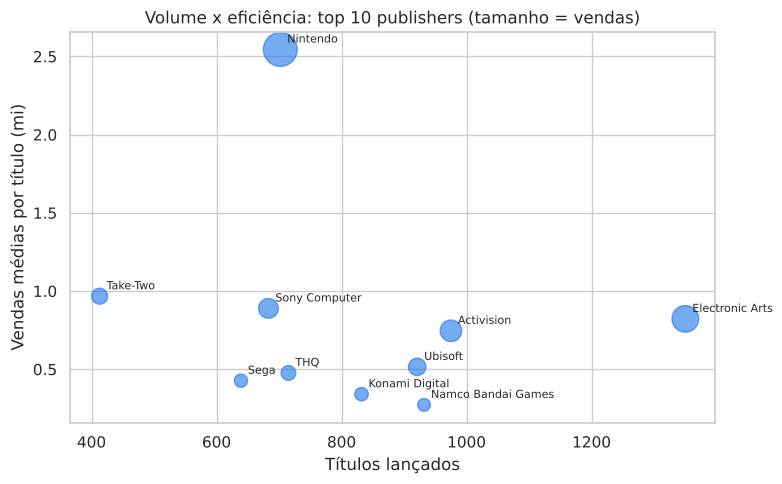

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(top_pub['titulos'], top_pub['media_por_titulo'], s=top_pub['vendas'] / 3, color=AZUL, alpha=.6)
for nome, r in top_pub.iterrows():
    ax.annotate(nome.replace(' Entertainment', '').replace(' Interactive', ''), (r.titulos, r.media_por_titulo),
                fontsize=8, xytext=(5, 5), textcoords='offset points')
ax.set(title='Volume x eficiência: top 10 publishers (tamanho = vendas)', xlabel='Títulos lançados', ylabel='Vendas médias por título (mi)')
plt.tight_layout(); plt.savefig(GRAF + '05_publishers.png', dpi=150); plt.show()

**Leitura:** a **Nintendo lidera em vendas (20%) e em eficiência**: vende em média 2,5 milhões por título, três vezes a média da Electronic Arts. A EA chega ao 2º lugar pelo volume (1.350 títulos, quase o dobro da Nintendo). São duas estratégias distintas: franquias próprias fortes contra catálogo amplo.

## Pergunta 7 — Quais gêneros vendem mais por título lançado?

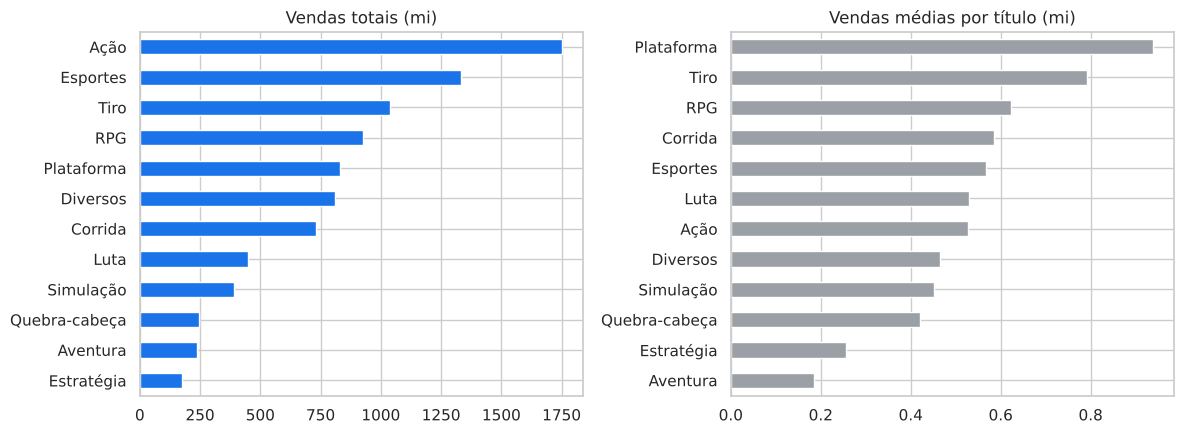

,vendas,titulos,mediana,media_por_titulo,share_%
Genero_PT,,,,,
Ação,"1,751.18",3316,0.19,0.53,19.63
Esportes,"1,330.93",2345,0.22,0.57,14.92
Tiro,"1,037.37",1309,0.23,0.79,11.63
RPG,927.37,1488,0.18,0.62,10.40
Plataforma,831.37,886,0.28,0.94,9.32
Diversos,809.96,1739,0.16,0.47,9.08
Corrida,732.04,1249,0.19,0.59,8.21
Luta,448.91,848,0.21,0.53,5.03
Simulação,392.20,867,0.16,0.45,4.40


In [13]:
gen = df.groupby('Genero_PT').agg(vendas=('Global_Sales', 'sum'), titulos=('Name', 'size'),
                                   mediana=('Global_Sales', 'median'))
gen['media_por_titulo'] = gen['vendas'] / gen['titulos']
gen['share_%'] = gen['vendas'] / gen['vendas'].sum() * 100
gen = gen.sort_values('vendas', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
gen['vendas'].sort_values().plot.barh(ax=axes[0], color=AZUL); axes[0].set(title='Vendas totais (mi)', ylabel='')
gen['media_por_titulo'].sort_values().plot.barh(ax=axes[1], color=CINZA); axes[1].set(title='Vendas médias por título (mi)', ylabel='')
plt.tight_layout(); plt.savefig(GRAF + '06_generos.png', dpi=150); plt.show()
gen.round(2)

**Leitura:** **Ação é o maior gênero em volume (20% das vendas), mas também o mais lotado** (3.316 títulos), com média de 0,53 mi por título. Já **Plataforma (0,94 mi) e Tiro (0,79 mi)** vendem bem mais por lançamento com bem menos concorrência.

**Implicação para o gestor:** volume total não é sinônimo de oportunidade. Gêneros com alta média por título e menos lançamentos indicam onde cada aposta tende a render mais. A mediana confirma a leitura: Plataforma (0,28 mi) e Tiro (0,23 mi) também lideram nesse critério, então não é só efeito de poucos *hits* como Mario.

## Conclusões

| # | Pergunta | Resposta curta |
| --- | --- | --- |
| 1 | Evolução do mercado | Auge da mídia física em 2008; queda após 2010 é parcialmente efeito da base |
| 2 | Dependência de hits | 1% dos títulos = ~21% das vendas; usar mediana para projetar |
| 3 | Regiões | América do Norte = 49%, Europa = 27%, Japão = 14,5% |
| 4 | Gênero x região | RPG domina no Japão (27%); Tiro é forte só no Ocidente |
| 5 | Fabricantes | Sony 40% x Nintendo 39,5%; PS2 é a plataforma líder |
| 6 | Publishers | Nintendo lidera em volume e eficiência (2,5 mi/título) |
| 7 | Gêneros | Ação lidera em volume; Plataforma e Tiro rendem mais por título |

**Próximos passos sugeridos:** cruzar com dados de receita e vendas digitais (que a base não tem) e com notas da crítica (Metacritic) para entender **por que** alguns títulos viram *hits*.